In [3]:
# ============================================================
# 1. Imports et reproductibilité
# ============================================================

!pip install -q scikit-learn pandas matplotlib openpyxl

import os
import json
import random
import zipfile
import datetime
import shutil

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)

from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.20.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# ============================================================
# 2. Décompression propre du dataset final
# ============================================================

BASE_DIR = Path("/content")

ZIP_PATH = (
    BASE_DIR /
    "dataset_final_splits_v2.zip"
)

SPLIT_DATA_DIR = (
    BASE_DIR /
    "dataset_final_splits_v2"
)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP introuvable : {ZIP_PATH}"
    )

# Supprimer un ancien dossier extrait
# pour éviter de conserver d'anciens fichiers
if SPLIT_DATA_DIR.exists():
    shutil.rmtree(SPLIT_DATA_DIR)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(BASE_DIR)

if not SPLIT_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dossier extrait introuvable : {SPLIT_DATA_DIR}"
    )

print("Dataset extrait proprement :", SPLIT_DATA_DIR)

Dataset extrait proprement : /content/dataset_final_splits_v2


In [5]:
# ============================================================
# 3. Configuration du dataset
# ============================================================

PROJECT_NAME = (
    "MALLOULINOVA_dataset_atelier_redmi_apexel"
)

CLASS_NAMES_TARGET = [
    "origine",
    "repeint"
]

NUM_CLASSES = len(CLASS_NAMES_TARGET)

IMG_SIZE = (384, 384)
BATCH_SIZE = 8

EPOCHS_PHASE1 = 10
EPOCHS_PHASE2 = 3

LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5
FINE_TUNE_LAST_N = 5

CONFIDENCE_THRESHOLD = 0.65

OUTPUT_DIR = (
    BASE_DIR /
    "outputs_training_atelier_v2"
)

for folder in [
    "weights",
    "metrics",
    "figures",
    "predictions",
]:
    (
        OUTPUT_DIR / folder
    ).mkdir(
        parents=True,
        exist_ok=True
    )

print("Classes :", CLASS_NAMES_TARGET)
print("Dataset :", SPLIT_DATA_DIR)
print("Sorties :", OUTPUT_DIR)

Classes : ['origine', 'repeint']
Dataset : /content/dataset_final_splits_v2
Sorties : /content/outputs_training_atelier_v2


In [6]:
# ============================================================
# 4. Vérification du dataset final
# ============================================================

distribution_rows = []

for split in ["train", "val", "test"]:

    for label in CLASS_NAMES_TARGET:

        folder = (
            SPLIT_DATA_DIR /
            split /
            label
        )

        if not folder.exists():
            raise FileNotFoundError(
                f"Dossier absent : {folder}"
            )

        count = len([
            path for path in folder.iterdir()
            if path.is_file()
        ])

        distribution_rows.append({
            "split": split,
            "label": label,
            "count": count,
        })

distribution_df = pd.DataFrame(
    distribution_rows
)

display(
    distribution_df.pivot(
        index="split",
        columns="label",
        values="count"
    )
)

print(
    "Total :",
    distribution_df["count"].sum()
)

label,origine,repeint
split,,
test,22,29
train,112,54
val,23,24


Total : 264


In [7]:
# ============================================================
# Réinitialisation TensorFlow avant un nouvel entraînement
# ============================================================

tf.keras.backend.clear_session()

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [8]:
# ============================================================
# 5. Chargement Keras
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds_raw.class_names

assert class_names == CLASS_NAMES_TARGET, (
    f"Classes inattendues : {class_names}"
)

train_file_paths = list(
    train_ds_raw.file_paths
)

val_file_paths = list(
    val_ds_raw.file_paths
)

test_file_paths = list(
    test_ds_raw.file_paths
)

train_ds = train_ds_raw.prefetch(AUTOTUNE)
val_ds = val_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

print("Classes :", class_names)
print("Train :", len(train_file_paths))
print("Val :", len(val_file_paths))
print("Test :", len(test_file_paths))

Found 166 files belonging to 2 classes.
Found 47 files belonging to 2 classes.
Found 51 files belonging to 2 classes.
Classes : ['origine', 'repeint']
Train : 166
Val : 47
Test : 51


In [9]:
# ============================================================
# 6. Poids des classes
# ============================================================

train_counts = []

for label in CLASS_NAMES_TARGET:

    folder = (
        SPLIT_DATA_DIR /
        "train" /
        label
    )

    count = len([
        path for path in folder.iterdir()
        if path.is_file()
    ])

    train_counts.append(count)

train_labels = []

for class_index, count in enumerate(train_counts):
    train_labels.extend(
        [class_index] * count
    )

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=np.array(train_labels)
)

class_weight = {
    index: float(weight)
    for index, weight in enumerate(weights)
}

print("Distribution train :", dict(
    zip(CLASS_NAMES_TARGET, train_counts)
))

print("Poids des classes :", class_weight)

Distribution train : {'origine': 112, 'repeint': 54}
Poids des classes : {0: 0.7410714285714286, 1: 1.537037037037037}


In [10]:
# ============================================================
# 7. Data augmentation
# ============================================================
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal",
            seed=SEED
        ),

        layers.RandomRotation(
            0.03,
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.03,
            width_factor=0.03,
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            seed=SEED
        ),

        layers.RandomContrast(
            0.08,
            seed=SEED
        ),

        layers.RandomBrightness(
            0.05,
            seed=SEED
        ),
    ],
    name="data_augmentation"
)

In [11]:
# ============================================================
# 8. Construction du modèle EfficientNet-B0 binaire
# ============================================================

TOP = 32
BOTTOM = 32
LEFT = 32
RIGHT = 32

def build_efficientnetb0_binary_model(
    img_size=(384, 384),
    num_classes=2,
    dense_units=128,
    dropout_1=0.5,
    dropout_2=0.3,
    l2_reg=1e-3,
):
    inputs = keras.Input(shape=img_size + (3,), name="input_image")

    # Augmentation active uniquement pendant training=True

    x = layers.Cropping2D(cropping=((TOP, BOTTOM),(LEFT, RIGHT)),name="crop_zone_utile")(inputs)
    x = layers.Resizing(height=384,width=384,name="resize_apres_crop")(x)

    x = data_augmentation(x)

    # API officielle EfficientNet ; dans certaines versions, cette fonction est un no-op
    # car EfficientNet intègre déjà la normalisation. La conserver garantit la compatibilité.
    x = tf.keras.applications.efficientnet.preprocess_input(x)

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,),
    )
    base_model.trainable = False

    # training=False garde les BatchNorm en mode inference, stable pour petit dataset.
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(dropout_1, name="dropout_head_1")(x)
    x = layers.Dense(
        dense_units,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(l2_reg),
        name="dense_texture_head",
    )(x)
    x = layers.Dropout(dropout_2, name="dropout_head_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="classification_softmax")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="efficientnetb0_binary_malloulinova")
    return model, base_model


model, base_model = build_efficientnetb0_binary_model(
    img_size=IMG_SIZE,
    num_classes=NUM_CLASSES,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()
print("Backbone:", base_model.name)
print("Backbone trainable:", base_model.trainable)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_binary_malloulinova"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ crop_zone_utile (Cropping2D)    │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_apres_crop (Resizing)    │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 12, 12, 1280)   │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_1 (Dropout)        │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_texture_head (Dense)      │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_2 (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_softmax (Dense)  │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Backbone: efficientnetb0
Backbone trainable: False


In [12]:
# ============================================================
# 9. Callbacks Phase 1
# ============================================================

checkpoint_phase1 = OUTPUT_DIR / "weights" / "efficientnet_binaire_phase1_best.keras"

callbacks_phase1 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase1),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint Phase 1 :", checkpoint_phase1)


Checkpoint Phase 1 : /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase1_best.keras


In [13]:
# ============================================================
# 10. Entraînement Phase 1 : backbone gelé
# ============================================================

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1,
    class_weight=class_weight,
)

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5960 - loss: 0.8827
Epoch 1: val_loss improved from None to 0.96816, saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase1_best.keras

Epoch 1: finished saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase1_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 31s 331ms/step - accuracy: 0.5783 - loss: 0.8718 - val_accuracy: 0.5957 - val_loss: 0.9682 - learning_rate: 0.0010
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6774 - loss: 0.7999
Epoch 2: val_loss improved from 0.96816 to 0.83635, saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase1_best.keras

Epoch 2: finished saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase1_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 199ms/step - accuracy: 0.7289 - loss: 0.7777 - val_accuracy: 0.6170 - val_loss: 0.8363 - learning_rate: 0.0010
Epoch 3

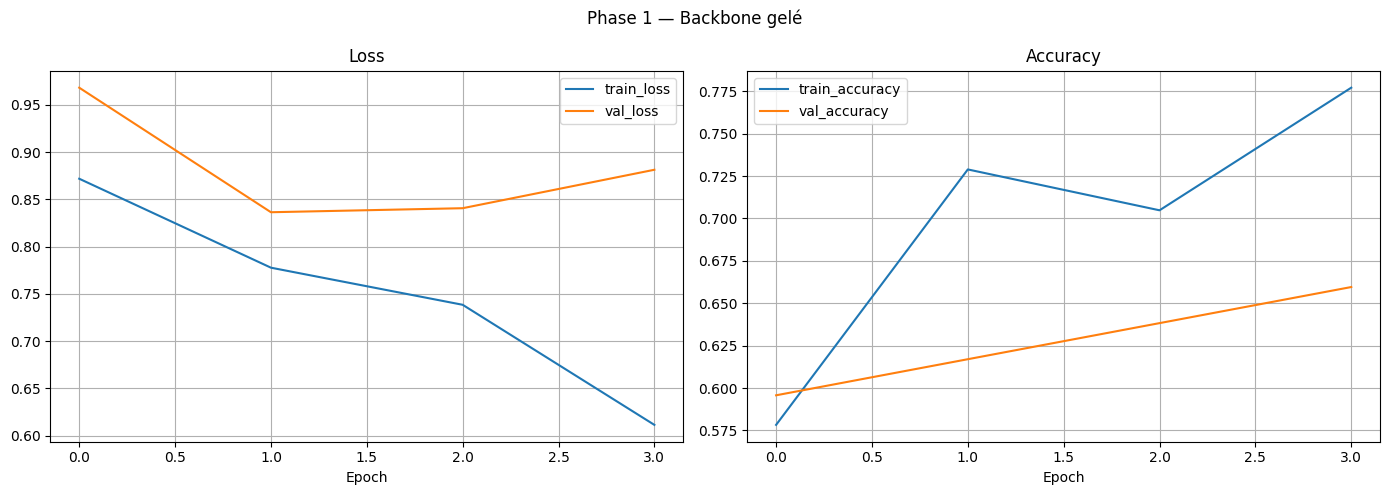

In [14]:
# ============================================================
# 11. Courbes Phase 1
# ============================================================


def plot_history(history, title="Historique d'entraînement"):
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist.get("loss", []), label="train_loss")
    axes[0].plot(hist.get("val_loss", []), label="val_loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(hist.get("accuracy", []), label="train_accuracy")
    axes[1].plot(hist.get("val_accuracy", []), label="val_accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history1, "Phase 1 — Backbone gelé")


In [15]:
# ============================================================
# 12. Fine-tuning Phase 2
# ============================================================

# Revenir au meilleur modèle de Phase 1
model.load_weights(
    str(checkpoint_phase1)
)

print("Meilleur checkpoint Phase 1 rechargé.")

base_model.trainable = True

# Geler toutes les couches sauf les N dernières
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False

# Garder toutes les BatchNorm gelées, même dans les couches dégelées
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(1 for layer in base_model.layers if layer.trainable)
n_total = len(base_model.layers)
print(f"Couches trainables du backbone : {n_trainable}/{n_total}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint_phase2 = OUTPUT_DIR / "weights" / "efficientnet_binaire_phase2_best.keras"

callbacks_phase2 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase2),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]
initial_epoch = len(history1.history.get("loss", []))
total_epochs = initial_epoch + EPOCHS_PHASE2

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=initial_epoch,
    callbacks=callbacks_phase2,
    class_weight=class_weight,
)


Meilleur checkpoint Phase 1 rechargé.
Couches trainables du backbone : 3/238
Epoch 5/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.6966 - loss: 0.6885
Epoch 5: val_loss improved from None to 0.89376, saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase2_best.keras

Epoch 5: finished saving model to /content/outputs_training_atelier_v2/weights/efficientnet_binaire_phase2_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 17s 306ms/step - accuracy: 0.6988 - loss: 0.7014 - val_accuracy: 0.6383 - val_loss: 0.8938 - learning_rate: 1.0000e-05
Epoch 6/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.7284 - loss: 0.7012
Epoch 6: val_loss did not improve from 0.89376

Epoch 6: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 205ms/step - accuracy: 0.7048 - loss: 0.7029 - val_accuracy: 0.6383 - val_loss: 0.9398 - learning_rate: 1.0000e-05
Epoch 7/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.7743

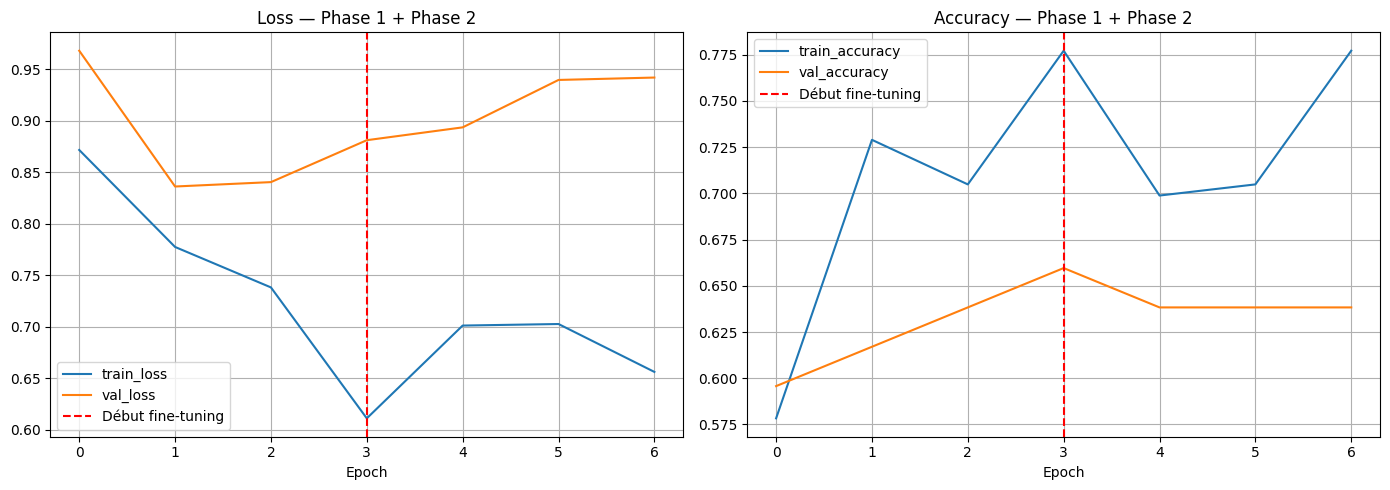

Courbes sauvegardées : /content/outputs_training_atelier_v2/figures/training_curves_phase1_phase2.png


In [16]:
# ============================================================
# 13. Courbes combinées Phase 1 + Phase 2
# ============================================================


def combine_histories(*histories):
    combined = {}
    for history in histories:
        for key, values in history.history.items():
            combined.setdefault(key, []).extend(values)
    return combined


combined_history = combine_histories(history1, history2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history.get("loss", []), label="train_loss")
axes[0].plot(combined_history.get("val_loss", []), label="val_loss")
axes[0].axvline(initial_epoch - 1, color="red", linestyle="--", label="Début fine-tuning")
axes[0].set_title("Loss — Phase 1 + Phase 2")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(combined_history.get("accuracy", []), label="train_accuracy")
axes[1].plot(combined_history.get("val_accuracy", []), label="val_accuracy")
axes[1].axvline(initial_epoch - 1, color="red", linestyle="--", label="Début fine-tuning")
axes[1].set_title("Accuracy — Phase 1 + Phase 2")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
history_fig_path = OUTPUT_DIR / "figures" / "training_curves_phase1_phase2.png"
plt.savefig(history_fig_path, dpi=150, bbox_inches="tight")
plt.show()

with open(OUTPUT_DIR / "metrics" / "training_history.json", "w", encoding="utf-8") as f:
    json.dump({k: [float(x) for x in v] for k, v in combined_history.items()}, f, indent=2)

print("Courbes sauvegardées :", history_fig_path)


In [17]:
# ============================================================
# 14. Modèle retenu
# ============================================================

chosen_model = model
chosen_model_name = "Phase 2"

POSITIVE_LABEL = "repeint"
POSITIVE_INDEX = 1

print("Modèle utilisé :", chosen_model_name)
print("Classe positive :", POSITIVE_LABEL)

Modèle utilisé : Phase 2
Classe positive : repeint


In [18]:
# ============================================================
# 15. Fonction de prédiction
# ============================================================

def collect_predictions(dataset, model):

    y_true_batches = []

    for _, labels in dataset:
        y_true_batches.append(
            np.argmax(
                labels.numpy(),
                axis=1
            )
        )

    y_true = np.concatenate(
        y_true_batches,
        axis=0
    )

    y_prob = model.predict(
        dataset,
        verbose=1
    )

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    return y_true, y_prob, y_pred

In [19]:
# ============================================================
# 16. Évaluation brute sur Test
# ============================================================

y_true_test, y_prob_test, y_pred_test = (
    collect_predictions(
        test_ds,
        chosen_model
    )
)

test_loss, test_accuracy_keras = (
    chosen_model.evaluate(
        test_ds,
        verbose=0
    )
)

accuracy_test = accuracy_score(
    y_true_test,
    y_pred_test
)

balanced_accuracy_test = balanced_accuracy_score(
    y_true_test,
    y_pred_test
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true_test,
        y_pred_test,
        labels=[0, 1],
        zero_division=0
    )
)

f1_macro_test = f1.mean()

print("Test loss :", round(float(test_loss), 4))
print("Accuracy :", round(float(accuracy_test), 4))
print(
    "Balanced accuracy :",
    round(float(balanced_accuracy_test), 4)
)
print(
    "F1 macro :",
    round(float(f1_macro_test), 4)
)
print(
    "Recall Repeint :",
    round(float(recall[1]), 4)
)
print(
    "F1 Repeint :",
    round(float(f1[1]), 4)
)

print(
    classification_report(
        y_true_test,
        y_pred_test,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    )
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 490ms/step
Test loss : 0.8098
Accuracy : 0.6863
Balanced accuracy : 0.7132
F1 macro : 0.6832
Recall Repeint : 0.5172
F1 Repeint : 0.6522
              precision    recall  f1-score   support

     origine       0.59      0.91      0.71        22
     repeint       0.88      0.52      0.65        29

    accuracy                           0.69        51
   macro avg       0.74      0.71      0.68        51
weighted avg       0.76      0.69      0.68        51



In [20]:
y_true_val, y_prob_val, _ = (
    collect_predictions(
        val_ds,
        chosen_model
    )
)

threshold_rows = []

for threshold in np.arange(
    0.20,
    0.61,
    0.01
):

    y_pred_val_threshold = (
        y_prob_val[:, POSITIVE_INDEX]
        >= threshold
    ).astype(int)

    precision_val, recall_val, f1_val, _ = (
        precision_recall_fscore_support(
            y_true_val,
            y_pred_val_threshold,
            labels=[0, 1],
            zero_division=0
        )
    )

    threshold_rows.append({
        "threshold_repeint": round(
            float(threshold),
            2
        ),
        "precision_repeint": precision_val[1],
        "recall_repeint": recall_val[1],
        "f1_repeint": f1_val[1],
        "f1_macro": f1_val.mean(),
        "balanced_accuracy": balanced_accuracy_score(
            y_true_val,
            y_pred_val_threshold
        )
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

display(
    threshold_df.sort_values(
        "f1_macro",
        ascending=False
    ).head(10)
)

best_row = threshold_df.loc[
    threshold_df["f1_macro"].idxmax()
]

BEST_REPEINT_THRESHOLD = float(
    best_row["threshold_repeint"]
)

print(
    "Seuil Repeint sélectionné :",
    BEST_REPEINT_THRESHOLD
)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step


,threshold_repeint,precision_repeint,recall_repeint,f1_repeint,f1_macro,balanced_accuracy
37,0.57,0.681818,0.625000,0.652174,0.659420,0.660326
36,0.56,0.681818,0.625000,0.652174,0.659420,0.660326
33,0.53,0.681818,0.625000,0.652174,0.659420,0.660326
32,0.52,0.681818,0.625000,0.652174,0.659420,0.660326
35,0.55,0.681818,0.625000,0.652174,0.659420,0.660326
34,0.54,0.681818,0.625000,0.652174,0.659420,0.660326
40,0.60,0.700000,0.583333,0.636364,0.658182,0.661232
24,0.44,0.652174,0.625000,0.638298,0.638298,0.638587
25,0.45,0.652174,0.625000,0.638298,0.638298,0.638587
27,0.47,0.652174,0.625000,0.638298,0.638298,0.638587


Seuil Repeint sélectionné : 0.52


In [21]:
# ============================================================
# 18. Seuil Incertain et verdict final
# ============================================================

proba_repeint_test = (
    y_prob_test[:, POSITIVE_INDEX]
)

confidence_test = np.max(
    y_prob_test,
    axis=1
)

raw_prediction_test = (
    proba_repeint_test
    >= BEST_REPEINT_THRESHOLD
).astype(int)

accepted_test = (
    confidence_test
    >= CONFIDENCE_THRESHOLD
)

verdict_final_test = []

for i in range(len(y_prob_test)):

    if not accepted_test[i]:
        verdict_final_test.append("incertain")

    elif raw_prediction_test[i] == 1:
        verdict_final_test.append("repeint")

    else:
        verdict_final_test.append("origine")

print("Nombre total :", len(verdict_final_test))
print(
    "Images acceptées :",
    int(accepted_test.sum())
)
print(
    "Images Incertain :",
    int((~accepted_test).sum())
)
print(
    "Taux Incertain :",
    round(
        float((~accepted_test).mean()),
        4
    )
)
print(
    "Couverture :",
    round(
        float(accepted_test.mean()),
        4
    )
)

Nombre total : 51
Images acceptées : 36
Images Incertain : 15
Taux Incertain : 0.2941
Couverture : 0.7059


In [22]:
# ============================================================
# 19. Export des résultats
# ============================================================

final_results_df = pd.DataFrame({
    "file_path": test_file_paths,
    "true_class": [
        class_names[i]
        for i in y_true_test
    ],
    "proba_origine": y_prob_test[:, 0],
    "proba_repeint": y_prob_test[:, 1],
    "raw_prediction": [
        class_names[i]
        for i in raw_prediction_test
    ],
    "confidence": confidence_test,
    "repaint_threshold": BEST_REPEINT_THRESHOLD,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "verdict_final": verdict_final_test,
    "accepted": accepted_test,
})

final_results_path = (
    OUTPUT_DIR /
    "predictions" /
    "predictions_finales_atelier.csv"
)

final_results_df.to_csv(
    final_results_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Résultats sauvegardés :",
    final_results_path
)

Résultats sauvegardés : /content/outputs_training_atelier_v2/predictions/predictions_finales_atelier.csv


AUC binaire classe positive 'repeint' : 0.6755


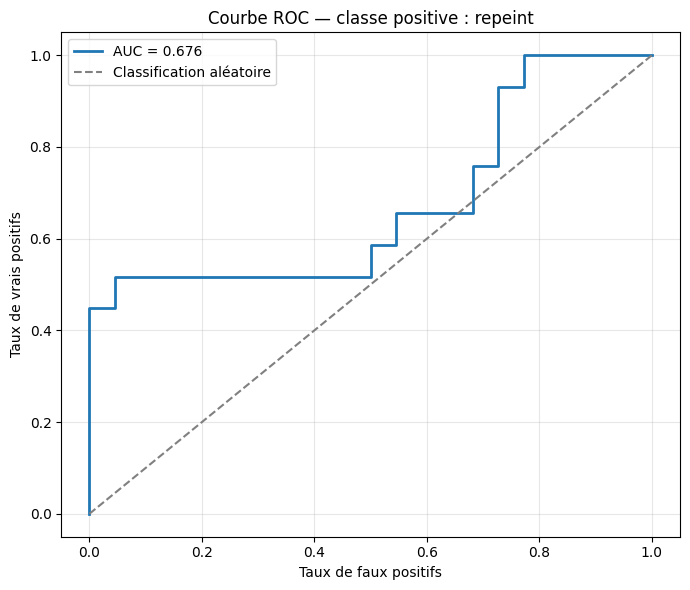

In [23]:
# ============================================================
# 20. AUC et courbe ROC
# ============================================================

try:
    auc_value = roc_auc_score(
        y_true_test,
        y_prob_test[:, POSITIVE_INDEX]
    )

    fpr, tpr, roc_thresholds = roc_curve(
        y_true_test,
        y_prob_test[:, POSITIVE_INDEX],
        pos_label=POSITIVE_INDEX
    )

    print(
        f"AUC binaire classe positive "
        f"'{POSITIVE_LABEL}' : {auc_value:.4f}"
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {auc_value:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Classification aléatoire"
    )

    plt.xlabel("Taux de faux positifs")
    plt.ylabel("Taux de vrais positifs")
    plt.title(
        f"Courbe ROC — classe positive : {POSITIVE_LABEL}"
    )

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    roc_path = (
        OUTPUT_DIR /
        "figures" /
        "roc_curve_test_atelier.png"
    )

    plt.savefig(
        roc_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

except ValueError as error:
    auc_value = None
    print("AUC non calculable :", error)

Matrice de confusion :
[[20  2]
 [14 15]]


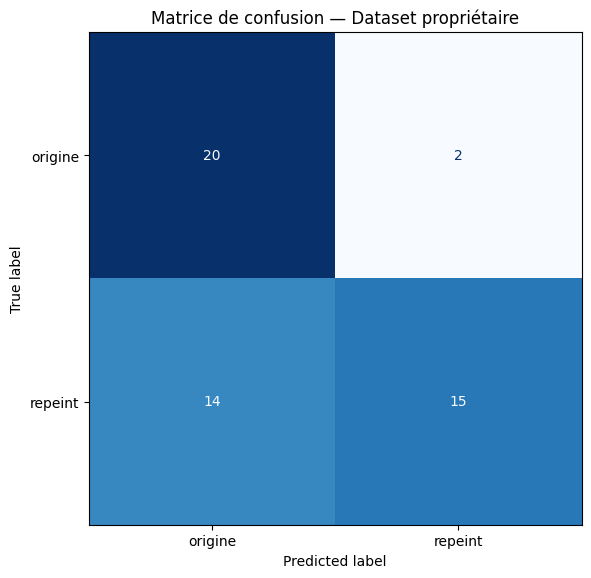

Matrice sauvegardée : /content/outputs_training_atelier_v2/figures/confusion_matrix_test_atelier.png


In [24]:
# ============================================================
# 21. Matrice de confusion
# ============================================================

cm = confusion_matrix(
    y_true_test,
    y_pred_test,
    labels=[0, 1]
)

print("Matrice de confusion :")
print(cm)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Matrice de confusion — Dataset propriétaire"
)

plt.tight_layout()

cm_path = (
    OUTPUT_DIR /
    "figures" /
    "confusion_matrix_test_atelier.png"
)

plt.savefig(
    cm_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Matrice sauvegardée :", cm_path)

In [25]:
# ============================================================
# 22. Analyse des erreurs
# ============================================================

index_to_class = {
    index: label
    for index, label in enumerate(class_names)
}


error_indices = np.where(
    y_true_test != y_pred_test
)[0]

print("=" * 60)
print(
    f"ERREURS : {len(error_indices)} "
    f"sur {len(y_true_test)} images"
)
print("=" * 60)

error_rows = []

for index in error_indices:

    error_rows.append({
        "file_path": test_file_paths[index],
        "filename": os.path.basename(
            test_file_paths[index]
        ),
        "true_class": index_to_class[
            int(y_true_test[index])
        ],
        "predicted_class": index_to_class[
            int(y_pred_test[index])
        ],
        "confidence": float(
            confidence_test[index]
        ),
        "confidence_percent": float(
            confidence_test[index] * 100
        ),
        "proba_origine": float(
            y_prob_test[index, 0]
        ),
        "proba_repeint": float(
            y_prob_test[index, 1]
        ),
    })

error_df = pd.DataFrame(error_rows)

if len(error_df) > 0:
    display(error_df)
else:
    print("Aucune erreur.")

error_path = (
    OUTPUT_DIR /
    "predictions" /
    "test_errors_atelier.csv"
)

error_df.to_csv(
    error_path,
    index=False,
    encoding="utf-8-sig"
)

print("Erreurs sauvegardées :", error_path)

ERREURS : 16 sur 51 images


,file_path,filename,true_class,predicted_class,confidence,confidence_percent,proba_origine,proba_repeint
0,/content/dataset_final_splits_v2/test/origine/...,image_186.jpeg,origine,repeint,0.609766,60.976555,0.390235,0.609766
1,/content/dataset_final_splits_v2/test/origine/...,image_188.jpeg,origine,repeint,0.517492,51.749229,0.482508,0.517492
2,/content/dataset_final_splits_v2/test/repeint/...,image_015.jpeg,repeint,origine,0.660732,66.073166,0.660732,0.339268
3,/content/dataset_final_splits_v2/test/repeint/...,image_016.jpeg,repeint,origine,0.692051,69.205139,0.692051,0.307949
4,/content/dataset_final_splits_v2/test/repeint/...,image_017.jpeg,repeint,origine,0.648381,64.838120,0.648381,0.351619
5,/content/dataset_final_splits_v2/test/repeint/...,image_018.jpeg,repeint,origine,0.714001,71.400078,0.714001,0.285999
6,/content/dataset_final_splits_v2/test/repeint/...,image_019.jpeg,repeint,origine,0.718638,71.863846,0.718638,0.281362
7,/content/dataset_final_splits_v2/test/repeint/...,image_020.jpeg,repeint,origine,0.713393,71.339325,0.713393,0.286607
8,/content/dataset_final_splits_v2/test/repeint/...,image_239.jpeg,repeint,origine,0.714001,71.400078,0.714001,0.285999
9,/content/dataset_final_splits_v2/test/repeint/...,image_240.jpeg,repeint,origine,0.660732,66.073166,0.660732,0.339268


Erreurs sauvegardées : /content/outputs_training_atelier_v2/predictions/test_errors_atelier.csv


In [26]:
# ============================================================
# 23. Résumé JSON
# ============================================================

metrics_summary = {
    "dataset_source": "MALLOULIAUTO_dataset_atelier",
    "dataset_type": "proprietary_pilot",
    "smartphone": "Redmi Note 12",
    "module": "Apexel",
    "input_size": list(IMG_SIZE),
    "classes": class_names,
    "positive_class_for_auc": POSITIVE_LABEL,
    "n_test_images": int(len(y_true_test)),
    "test_loss": float(test_loss),
    "test_accuracy_keras": float(
        test_accuracy_keras
    ),
    "accuracy_sklearn": float(
        accuracy_test
    ),
    "balanced_accuracy": float(
        balanced_accuracy_test
    ),
    "precision_macro": float(
        precision.mean()
    ),
    "recall_macro": float(
        recall.mean()
    ),
    "f1_macro": float(
        f1_macro_test
    ),
    "precision_origine": float(
        precision[0]
    ),
    "recall_origine": float(
        recall[0]
    ),
    "f1_origine": float(
        f1[0]
    ),
    "precision_repeint": float(
        precision[1]
    ),
    "recall_repeint": float(
        recall[1]
    ),
    "f1_repeint": float(
        f1[1]
    ),
    "auc_repeint": (
        float(auc_value)
        if auc_value is not None
        else None
    ),
    "n_errors": int(len(error_indices)),
    "error_rate": float(
        len(error_indices) / len(y_true_test)
    ),
    "timestamp": datetime.datetime.now().isoformat(),
}

summary_path = (
    OUTPUT_DIR /
    "metrics" /
    "metrics_summary_test_atelier.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metrics_summary,
        file,
        indent=2,
        ensure_ascii=False
    )

print(
    json.dumps(
        metrics_summary,
        indent=2,
        ensure_ascii=False
    )
)

print(
    "Résumé sauvegardé :",
    summary_path
)


{
  "dataset_source": "MALLOULIAUTO_dataset_atelier",
  "dataset_type": "proprietary_pilot",
  "smartphone": "Redmi Note 12",
  "module": "Apexel",
  "input_size": [
    384,
    384
  ],
  "classes": [
    "origine",
    "repeint"
  ],
  "positive_class_for_auc": "repeint",
  "n_test_images": 51,
  "test_loss": 0.8098499178886414,
  "test_accuracy_keras": 0.686274528503418,
  "accuracy_sklearn": 0.6862745098039216,
  "balanced_accuracy": 0.713166144200627,
  "precision_macro": 0.7352941176470589,
  "recall_macro": 0.713166144200627,
  "f1_macro": 0.6832298136645962,
  "precision_origine": 0.5882352941176471,
  "recall_origine": 0.9090909090909091,
  "f1_origine": 0.7142857142857143,
  "precision_repeint": 0.8823529411764706,
  "recall_repeint": 0.5172413793103449,
  "f1_repeint": 0.6521739130434783,
  "auc_repeint": 0.6755485893416928,
  "n_errors": 16,
  "error_rate": 0.3137254901960784,
  "timestamp": "2026-08-24T10:39:58.245186"
}
Résumé sauvegardé : /content/outputs_training_ateli